# 01 · Data understanding and exploratory analysis

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Questions
What was recorded, when was it recorded, and which patterns require engineering context? Read the column dictionary in `docs/dataset.md` before interpreting digital signal polarity. The released data span is measured, not assumed from its description.

In [2]:
display(pd.Series({k:quality[k] for k in ['raw_rows','clean_rows','start','end','median_interval_seconds','p99_interval_seconds','estimated_calendar_coverage']}))
summary=pd.read_csv(OUT/'sensor_summary.csv',index_col='sensor')
display(summary)


raw_rows                                   1516948
clean_rows                                 1516948
start                          2020-02-01 00:00:00
end                            2020-09-01 03:59:50
median_interval_seconds                       10.0
p99_interval_seconds                          12.0
estimated_calendar_coverage                0.82364
dtype: object

,count,mean,std,min,1%,5%,50%,95%,99%,max
sensor,,,,,,,,,,
TP2,1516948.0,1.367826,3.250930,-0.032,-0.024,-0.0160,-0.012,9.5900,10.3520,10.676
TP3,1516948.0,8.984611,0.639095,0.730,7.876,8.1380,8.960,9.9800,10.1400,10.302
H1,1516948.0,7.568155,3.333200,-0.036,-0.024,-0.0140,8.784,9.9160,10.1140,10.288
DV_pressure,1516948.0,0.055956,0.382402,-0.032,-0.026,-0.0240,-0.020,-0.0080,2.1120,9.844
Reservoirs,1516948.0,8.985233,0.638307,0.712,7.876,8.1400,8.960,9.9780,10.1380,10.300
Oil_temperature,1516948.0,62.644182,6.516261,15.400,48.825,52.3250,62.700,73.5250,76.1750,89.050
Motor_current,1516948.0,2.050171,2.302053,0.020,0.035,0.0375,0.045,5.9875,6.1875,9.295
COMP,1516948.0,0.836957,0.369405,0.000,0.000,0.0000,1.000,1.0000,1.0000,1.000
DV_eletric,1516948.0,0.160611,0.367172,0.000,0.000,0.0000,0.000,1.0000,1.0000,1.000


## Sensor distributions
Histograms below use five-minute means, so they describe sustained operating conditions rather than the complete distribution of individual readings. Raw-reading quantiles above retain extremes.

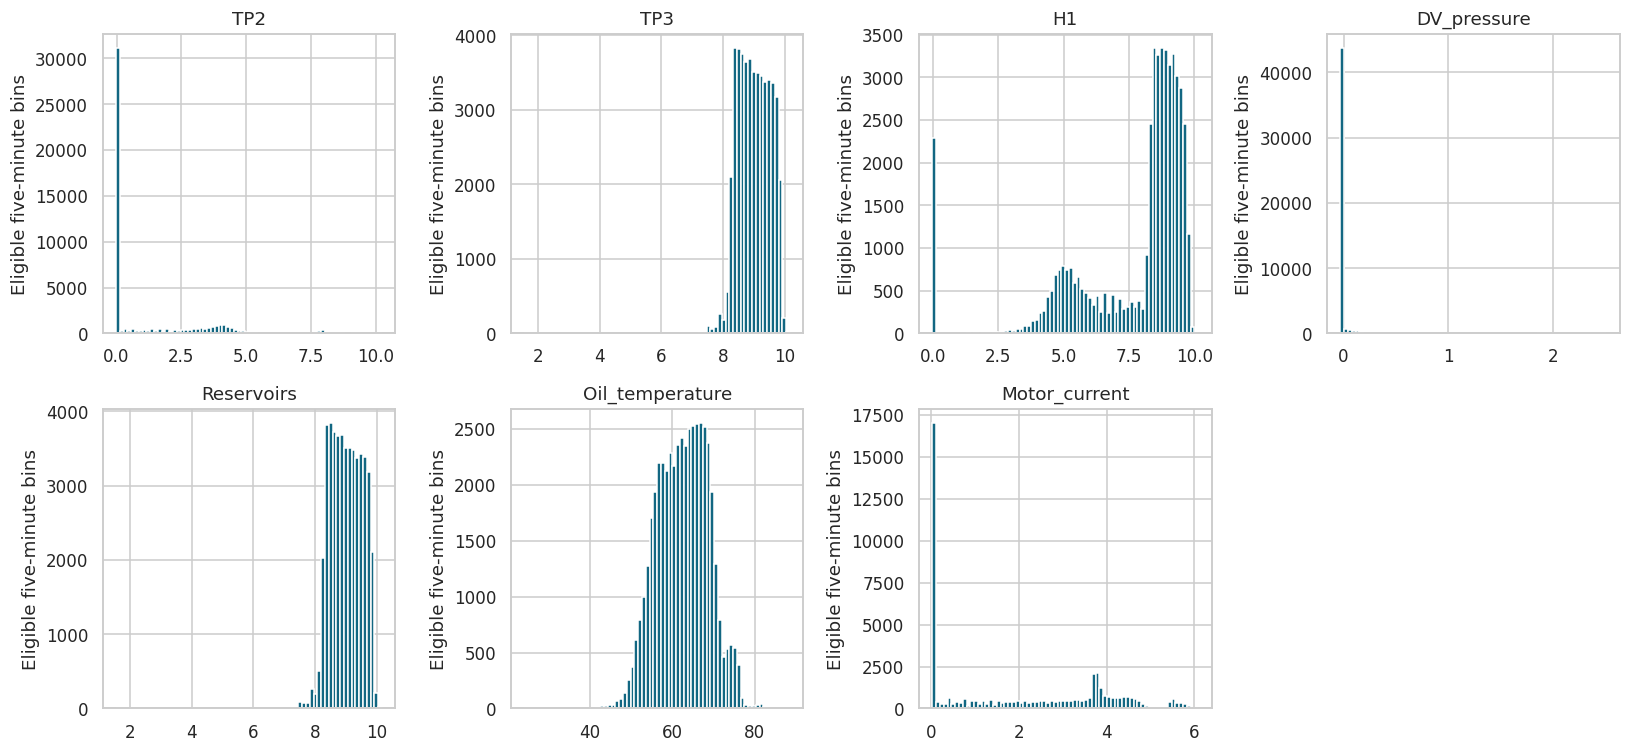

In [3]:
fig,axs=plt.subplots(2,4,figsize=(15,7))
for ax,c in zip(axs.flat,ANALOG):
    ax.hist(x.loc[x.quality_eligible,c].dropna(),bins=70,color='#126782')
    ax.set(title=c,ylabel='Eligible five-minute bins')
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()


,readings,calendar_coverage,eligible_bins,pressure,current,temperature
timestamp,,,,,,
2020-02-01,214850,0.850106,7079,8.963534,1.251209,56.287890
2020-03-01,230417,0.852823,7586,9.035101,2.087388,62.149112
2020-04-01,198765,0.760567,6188,9.025437,1.873319,59.407599
2020-05-01,212800,0.788011,6597,8.886569,2.000251,62.192830
2020-06-01,216483,0.828711,6376,8.882874,2.726917,65.683942
2020-07-01,222639,0.824201,7177,9.010649,2.297280,66.980930
2020-08-01,220464,0.815968,7260,9.040567,2.144918,65.149969
2020-09-01,530,0.357823,16,9.105966,2.124595,58.287363


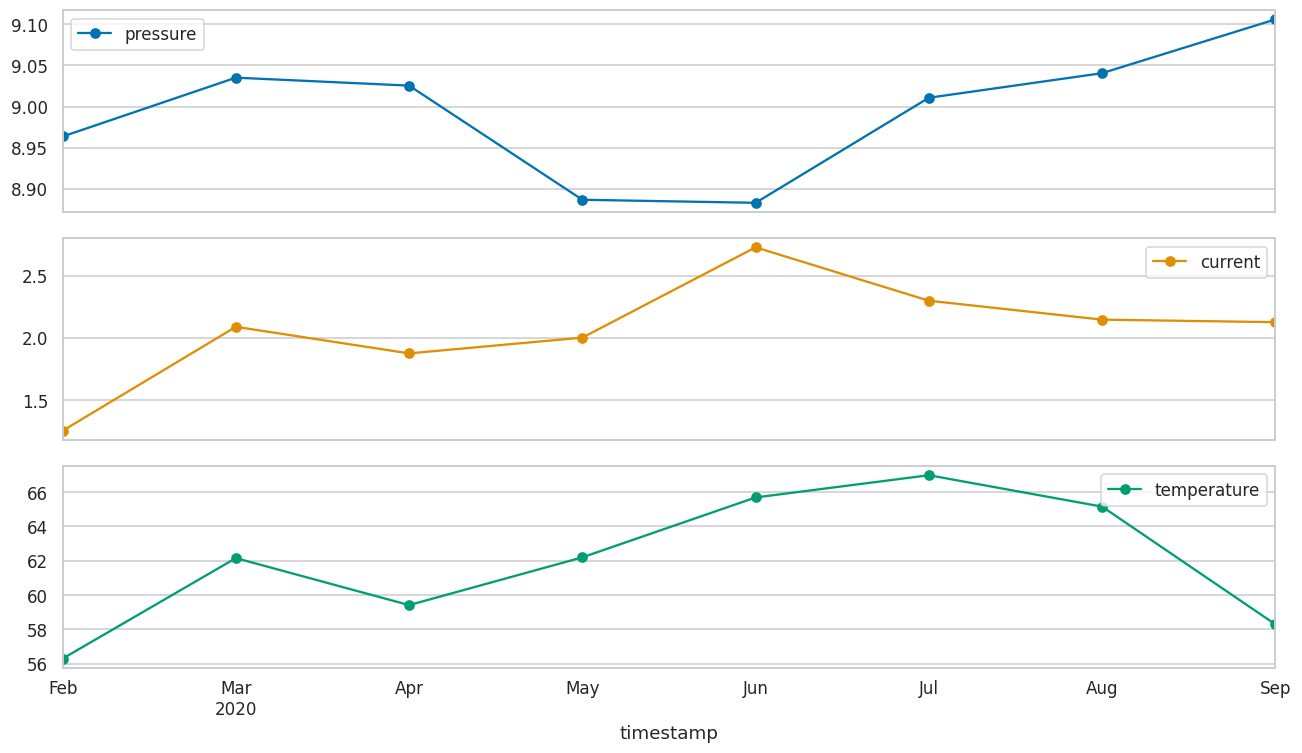

In [4]:
monthly=x.resample('MS').agg(readings=('sample_count','sum'),calendar_coverage=('availability','mean'),eligible_bins=('quality_eligible','sum'),pressure=('TP3','mean'),current=('Motor_current','mean'),temperature=('Oil_temperature','mean'))
display(monthly)
monthly[['pressure','current','temperature']].plot(subplots=True,figsize=(12,7),marker='o'); plt.tight_layout(); plt.show()


## Documented events
Intervals are reported air-leak periods, not per-reading labels. Their source has inconsistent maintenance metadata; only interval boundaries are used. A reported interval does not establish that the train was out of service.

In [5]:
display(events[['event_id','start','end','notes']])
display(x.groupby('split').agg(bins=('sample_count','size'),eligible=('quality_eligible','sum'),event_bins=('event_window','sum')))

,event_id,start,end,notes
0,E01,2020-04-18 00:00:00,2020-04-18 23:59:00,Reported interval; not verified outage
1,E02,2020-05-29 23:30:00,2020-05-30 06:00:00,Source repeats event number 1 and gives incons...
2,E03,2020-06-05 10:00:00,2020-06-07 14:30:00,Reported interval; not verified outage
3,E04,2020-07-15 14:30:00,2020-07-15 19:00:00,Reported interval; not verified outage


,bins,eligible,event_bins
split,,,
test,44113,33614,1053
train,8351,7079,0
validation,8928,7586,0


## Interpretation
Use the measured roughly ten-second cadence for coverage. Seasonal variation, loaded operation and telemetry artifacts can all change sensor distributions. Neither an extreme reading nor a change in a monthly mean establishes mechanical failure. The later notebooks separate those explanations.